# DDS-8555 Assignment 2: Build Regression Models
**Nathan Weber** · National University · DDS-8555: Predictive Analysis · Dr. Alexander Watt

**How to run:** Runtime → Run all. Approve the Google Drive prompt. The two Kaggle submission files download automatically and are also saved to Drive → DDS8555 → output.

| Section | What it covers |
|---|---|
| Textbook conceptual question (ISLP Ch. 3, Q3) | Part 1 |
| Textbook applied question (ISLP Ch. 3, Q10) | Part 2 |
| Two Kaggle models | Part 3 (two submission files) |
| Kaggle submission evidence | Screenshot in the paper's appendix |
| Assumption checks | Part 3, assumption checks (linearity, independence, constant variance, normality, collinearity) |
| Code | This notebook (also on GitHub) |

In [1]:
# ---- 0. Setup: runs in Google Colab (also runs locally) ----
import sys, os, glob, zipfile, json, warnings
warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, files
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/DDS8555/abalone"
    OUT_DIR = "/content/drive/MyDrive/DDS8555/output"
    !pip -q install --no-deps ISLP
else:
    DATA_DIR = os.environ.get("DDS8555_DATA", "data")
    OUT_DIR = os.environ.get("DDS8555_OUT", "output")
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from ISLP import load_data
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}          # every number the paper uses is stored here and printed at the end

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Part 1. Conceptual Question 3 (ISLP Chapter 3)
*Paraphrased:* salary (in $1,000s) is regressed on GPA, IQ, Level (1 = college, 0 = high school), GPA × IQ, and GPA × Level. The estimates are β̂0 = 50, β̂1 = 20, β̂2 = 0.07, β̂3 = 35, β̂4 = 0.01, β̂5 = −10.

**(a)** For fixed IQ and GPA, the college-minus-high-school gap is β̂3 + β̂5·GPA = 35 − 10·GPA. The gap is positive when GPA < 3.5 and negative when GPA > 3.5. **Answer iii is correct:** high school graduates earn more on average than college graduates, provided the GPA is high enough (above 3.5).

**(b)** College graduate, IQ = 110, GPA = 4.0: 50 + 20(4) + 0.07(110) + 35 + 0.01(4)(110) − 10(4) = **137.1, or $137,100** (checked in the next cell).

**(c)** **False.** The size of a coefficient depends on the units of its predictor. GPA × IQ takes values in the hundreds, so 0.01 per unit is not small. Evidence for an interaction comes from the coefficient's standard error, its *t* statistic and *p* value, or a model comparison, not from its magnitude.

In [2]:
b = dict(b0=50, gpa=20, iq=0.07, level=35, gpa_iq=0.01, gpa_level=-10)
gpa, iq, level = 4.0, 110, 1
salary = b["b0"] + b["gpa"]*gpa + b["iq"]*iq + b["level"]*level + b["gpa_iq"]*gpa*iq + b["gpa_level"]*gpa*level
print(f"(b) predicted salary = {salary:.1f} thousand dollars")
print(f"(a) college-minus-high-school gap is zero at GPA = {-b['level']/b['gpa_level']:.2f}")
for g in (3.0, 3.5, 4.0):
    print(f"    GPA {g}: college minus high school = {b['level'] + b['gpa_level']*g:+.1f}")

(b) predicted salary = 137.1 thousand dollars
(a) college-minus-high-school gap is zero at GPA = 3.50
    GPA 3.0: college minus high school = +5.0
    GPA 3.5: college minus high school = +0.0
    GPA 4.0: college minus high school = -5.0


## Part 2. Applied Question 10 (ISLP Chapter 3): Carseats
(a) Fit Sales on Price, Urban, and US. (b) Interpret each coefficient. (c) Write the model as an equation. (d) Decide where H0: βj = 0 can be rejected. (e) Fit a smaller model. (f) Compare fit. (g) Give 95% confidence intervals. (h) Look for outliers and high-leverage points.

In [3]:
carseats = load_data("Carseats")
fit_a = smf.ols("Sales ~ Price + Urban + US", data=carseats).fit()
print(fit_a.summary().tables[1])
print(f"R-squared {fit_a.rsquared:.4f}, adjusted {fit_a.rsquared_adj:.4f}, RSE {np.sqrt(fit_a.scale):.4f}, F {fit_a.fvalue:.2f}")

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       13.0435      0.651     20.036      0.000      11.764      14.323
Urban[T.Yes]    -0.0219      0.272     -0.081      0.936      -0.556       0.512
US[T.Yes]        1.2006      0.259      4.635      0.000       0.691       1.710
Price           -0.0545      0.005    -10.389      0.000      -0.065      -0.044
R-squared 0.2393, adjusted 0.2335, RSE 2.4725, F 41.52


**(b) Interpretation.** Sales are in thousands of units and Price is in dollars.
* **Price:** holding Urban and US fixed, each $1 increase in price is associated with about 54 fewer car seats sold (−0.0545 thousand).
* **Urban[Yes]:** urban stores sell about 22 fewer units than rural stores, but the estimate is indistinguishable from zero (*p* = .94).
* **US[Yes]:** US stores sell about 1,200 more units than non-US stores (*p* < .001).

**(c) Equation:** Sales = 13.04 − 0.0545·Price − 0.0219·Urban + 1.2006·US + ε, where Urban = 1 for urban stores and US = 1 for US stores (0 otherwise).

**(d)** H0 is rejected for **Price** and **US**. It is not rejected for **Urban**.

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     13.0308      0.631     20.652      0.000      11.790      14.271
US[T.Yes]      1.1996      0.258      4.641      0.000       0.692       1.708
Price         -0.0545      0.005    -10.416      0.000      -0.065      -0.044
   df_resid          ssr  df_diff  ss_diff         F    Pr(>F)
0     397.0  2420.874462      0.0      NaN       NaN       NaN
1     396.0  2420.834671      1.0  0.03979  0.006509  0.935739
(a) R2 0.2393  adj R2 0.2335  RSE 2.4725
(e) R2 0.2393  adj R2 0.2354  RSE 2.4694

(g) 95% confidence intervals, model (e):
                 0        1
Intercept  11.7903  14.2713
US[T.Yes]   0.6915   1.7078
Price      -0.0648  -0.0442

(h) average leverage (p+1)/n = 0.0075; max leverage = 0.0433 (5.8x average)
    points above 2x average leverage: 20; above 3x: 6
    max |studentized residual| = 2.89; count abov

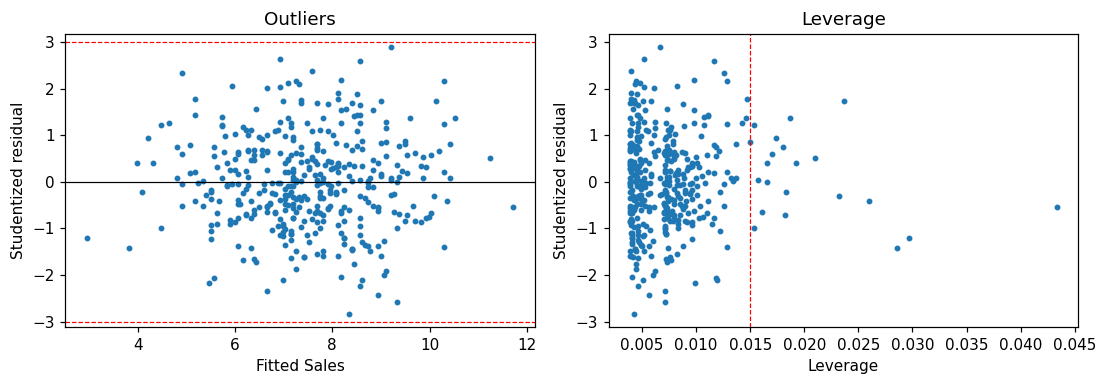

In [4]:
fit_e = smf.ols("Sales ~ Price + US", data=carseats).fit()
print(fit_e.summary().tables[1])
from statsmodels.stats.anova import anova_lm
print(anova_lm(fit_e, fit_a))
print(f"(a) R2 {fit_a.rsquared:.4f}  adj R2 {fit_a.rsquared_adj:.4f}  RSE {np.sqrt(fit_a.scale):.4f}")
print(f"(e) R2 {fit_e.rsquared:.4f}  adj R2 {fit_e.rsquared_adj:.4f}  RSE {np.sqrt(fit_e.scale):.4f}")
print("\n(g) 95% confidence intervals, model (e):"); print(fit_e.conf_int().round(4))

infl = fit_e.get_influence()
h = infl.hat_matrix_diag; sr = infl.resid_studentized_external
p_avg = (fit_e.df_model + 1) / fit_e.nobs
print(f"\n(h) average leverage (p+1)/n = {p_avg:.4f}; max leverage = {h.max():.4f} ({h.max()/p_avg:.1f}x average)")
print(f"    points above 2x average leverage: {(h > 2*p_avg).sum()}; above 3x: {(h > 3*p_avg).sum()}")
print(f"    max |studentized residual| = {np.abs(sr).max():.2f}; count above 3: {(np.abs(sr) > 3).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(fit_e.fittedvalues, sr, s=8); ax[0].axhline(0, c="k", lw=.8)
ax[0].axhline(3, ls="--", c="r", lw=.8); ax[0].axhline(-3, ls="--", c="r", lw=.8)
ax[0].set_xlabel("Fitted Sales"); ax[0].set_ylabel("Studentized residual"); ax[0].set_title("Outliers")
ax[1].scatter(h, sr, s=8); ax[1].axvline(2*p_avg, ls="--", c="r", lw=.8)
ax[1].set_xlabel("Leverage"); ax[1].set_ylabel("Studentized residual"); ax[1].set_title("Leverage")
plt.tight_layout(); plt.show()
RESULTS["carseats"] = {"r2_a": fit_a.rsquared, "r2_e": fit_e.rsquared, "adjr2_a": fit_a.rsquared_adj,
                       "adjr2_e": fit_e.rsquared_adj, "rse_a": float(np.sqrt(fit_a.scale)), "rse_e": float(np.sqrt(fit_e.scale)),
                       "urban_p": float(fit_a.pvalues["Urban[T.Yes]"]), "max_lev_ratio": float(h.max()/p_avg),
                       "max_abs_sr": float(np.abs(sr).max())}

**(e)** The smaller model keeps only Price and US.

**(f)** Both models explain about 24% of the variance in Sales (R² ≈ .239). Dropping Urban leaves R² essentially unchanged, raises adjusted R² slightly, and lowers RSE slightly. The *F* test comparing the two models agrees (*p* = .94). Both fit only modestly: most of the variation in Sales comes from predictors not in the model.

**(g)** Price: [−0.0648, −0.0442]. US: [0.692, 1.708]. Neither interval contains 0.

**(h)** No studentized residual exceeds 3 in absolute value, so there are no clear outliers. A handful of points have leverage two to six times the average (p + 1)/n, but none combines high leverage with a large residual, so none looks influential.

## Kaggle data: Regression with an Abalone Dataset (Playground Series S4E4)
The data load and cleaning cell is identical in Assignments 2, 3, and 4, so the three notebooks use the same data.
Put the Kaggle download (the zip, or `train.csv`, `test.csv`, `sample_submission.csv`) in **Google Drive → My Drive → DDS8555 → abalone**. If the files are not there, an upload button appears.

**Cleaning rule (kept the same in A2–A4):** a height of 0 is physically impossible, so it is treated as missing and replaced with the training-set median height for that sex. Nothing else is changed. The target is modeled as log(1 + Rings) because the competition is scored by RMSLE (root mean squared logarithmic error).

In [5]:
# ---- Load and clean the Kaggle abalone data (same cell in A2, A3, A4) ----
for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
    with zipfile.ZipFile(z) as f:
        f.extractall(DATA_DIR)
NEED = ["train.csv", "test.csv", "sample_submission.csv"]
if IN_COLAB and not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in NEED):
    print("Choose the Kaggle zip (or the three CSV files):")
    for name, data in files.upload().items():
        open(os.path.join(DATA_DIR, name), "wb").write(data)
    for z in glob.glob(os.path.join(DATA_DIR, "*.zip")):
        zipfile.ZipFile(z).extractall(DATA_DIR)
missing = [f for f in NEED if not os.path.exists(os.path.join(DATA_DIR, f))]
assert not missing, f"Missing files in {DATA_DIR}: {missing}"

RENAME = {"whole weight": "whole_wt", "whole weight.1": "shucked_wt", "whole weight.2": "viscera_wt",
          "shucked weight": "shucked_wt", "viscera weight": "viscera_wt", "shell weight": "shell_wt",
          "whole_weight": "whole_wt", "shucked_weight": "shucked_wt", "viscera_weight": "viscera_wt",
          "shell_weight": "shell_wt"}
tidy = lambda d: d.rename(columns=lambda c: RENAME.get(c.strip().lower(), c.strip().lower()))
train_raw = tidy(pd.read_csv(os.path.join(DATA_DIR, "train.csv")))
test_raw = tidy(pd.read_csv(os.path.join(DATA_DIR, "test.csv")))
sample = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))
NUM = ["length", "diameter", "height", "whole_wt", "shucked_wt", "viscera_wt", "shell_wt"]
print("train:", train_raw.shape, " test:", test_raw.shape)
print("columns:", list(train_raw.columns))

HEIGHT_MED = train_raw.loc[train_raw.height > 0].groupby("sex")["height"].median()

def prepare(df):
    """Impute impossible zero heights; one-hot Sex with F as the baseline."""
    out = df.copy()
    zero = out["height"] <= 0
    out.loc[zero, "height"] = out.loc[zero, "sex"].map(HEIGHT_MED)
    sex = pd.Categorical(out["sex"], categories=["F", "I", "M"])
    X = pd.concat([out[NUM].astype(float),
                   pd.get_dummies(sex, prefix="sex", drop_first=True, dtype=float).set_index(out.index)], axis=1)
    return X, int(zero.sum())

X, zero_tr = prepare(train_raw)
X_test, zero_te = prepare(test_raw)
y = train_raw["rings"].astype(float)
ylog = np.log1p(y)
print(f"missing values: train {int(train_raw.isna().sum().sum())}, test {int(test_raw.isna().sum().sum())}")
print(f"zero heights imputed: train {zero_tr}, test {zero_te}")
print(f"duplicate rows (excluding id): {int(train_raw.drop(columns='id').duplicated().sum())}")
print("sex counts:", train_raw["sex"].value_counts().to_dict())
print(train_raw[NUM + ["rings"]].describe().T.round(3))
RESULTS["data"] = {"n_train": int(len(X)), "n_test": int(len(X_test)), "zero_height_train": zero_tr,
                   "zero_height_test": zero_te, "missing_train": int(train_raw.isna().sum().sum()),
                   "rings_min": float(y.min()), "rings_max": float(y.max()),
                   "rings_mean": float(y.mean()), "rings_skew": float(y.skew())}

# ---- Shared scoring helpers ----
from sklearn.model_selection import KFold, cross_val_predict
KF = KFold(n_splits=5, shuffle=True, random_state=42)
LO, HI = float(y.min()), float(y.max())

def rmsle(y_true, y_pred):
    return float(np.sqrt(np.mean((np.log1p(y_true) - np.log1p(y_pred)) ** 2)))

def cv_rmsle(model, XX, target="log"):
    """5-fold CV RMSLE on the training set. target='log' fits log1p(Rings)."""
    t = ylog if target == "log" else y
    p = cross_val_predict(model, XX, t, cv=KF)
    p = np.expm1(p) if target == "log" else p
    return rmsle(y, np.clip(p, LO, HI))

def write_submission(pred, name):
    sub = pd.DataFrame({sample.columns[0]: test_raw["id"].values,
                        sample.columns[1]: np.clip(pred, LO, HI)})
    path = os.path.join(OUT_DIR, name)
    sub.to_csv(path, index=False)
    print("saved", path, sub.shape)
    if IN_COLAB:
        files.download(path)
    return path

def resid_panel(fitted, resid, title, ax_row):
    ax1, ax2 = ax_row
    ax1.scatter(fitted, resid, s=2, alpha=.25)
    ax1.axhline(0, color="k", lw=.8)
    ax1.set_xlabel("Fitted value"); ax1.set_ylabel("Residual"); ax1.set_title(title + ": residuals vs fitted")
    sm.qqplot(resid, line="s", ax=ax2, markersize=2, alpha=.3)
    ax2.set_title(title + ": normal Q-Q")

def diagnostics(resid, exog):
    """Breusch-Pagan, Durbin-Watson, Jarque-Bera on a fitted model's residuals."""
    bp = het_breuschpagan(resid, sm.add_constant(exog, has_constant="add"))
    jb = jarque_bera(resid)
    return {"bp_stat": float(bp[0]), "bp_p": float(bp[1]), "dw": float(durbin_watson(resid)),
            "jb_stat": float(jb[0]), "skew": float(jb[2]), "kurtosis": float(jb[3])}

train: (90615, 10)  test: (60411, 9)
columns: ['id', 'sex', 'length', 'diameter', 'height', 'whole_wt', 'shucked_wt', 'viscera_wt', 'shell_wt', 'rings']
missing values: train 0, test 0
zero heights imputed: train 6, test 2
duplicate rows (excluding id): 0
sex counts: {'I': 33093, 'M': 31027, 'F': 26495}
              count   mean    std    min    25%    50%     75%     max
length      90615.0  0.517  0.118  0.075  0.445  0.545   0.600   0.815
diameter    90615.0  0.402  0.098  0.055  0.345  0.425   0.470   0.650
height      90615.0  0.135  0.038  0.000  0.110  0.140   0.160   1.130
whole_wt    90615.0  0.789  0.458  0.002  0.419  0.800   1.068   2.826
shucked_wt  90615.0  0.341  0.204  0.001  0.178  0.330   0.463   1.488
viscera_wt  90615.0  0.169  0.101  0.000  0.086  0.166   0.232   0.760
shell_wt    90615.0  0.226  0.130  0.002  0.120  0.225   0.305   1.005
rings       90615.0  9.697  3.176  1.000  8.000  9.000  11.000  29.000


## Part 3. Two regression models for Rings
* **Model 1 (baseline):** ordinary least squares (OLS) on the **raw** ring count, with all seven measurements plus Sex dummies. Sex is a categorical variable coded as two dummy variables, with female as the baseline.
* **Model 2:** OLS on **log(1 + Rings)**, with the same predictors plus a **Sex × shell weight interaction**. The log scale matches the competition metric (RMSLE). The interaction lets the shell-weight slope differ between infants and adults.

Both models are linear in their coefficients, so the classic regression assumptions apply to each: linearity, independent errors, constant error variance, normally distributed errors, and no severe collinearity.

In [6]:
X2 = X.copy()
X2["shell_x_I"] = X2["shell_wt"] * X2["sex_I"]
X2["shell_x_M"] = X2["shell_wt"] * X2["sex_M"]
X2_test = X_test.copy()
X2_test["shell_x_I"] = X2_test["shell_wt"] * X2_test["sex_I"]
X2_test["shell_x_M"] = X2_test["shell_wt"] * X2_test["sex_M"]

m1 = sm.OLS(y, sm.add_constant(X)).fit()
m2 = sm.OLS(ylog, sm.add_constant(X2)).fit()
print("MODEL 1: OLS, raw Rings"); print(m1.summary().tables[1])
print(f"R2 {m1.rsquared:.4f}  adj R2 {m1.rsquared_adj:.4f}  RSE {np.sqrt(m1.scale):.4f} rings")
print("\nMODEL 2: OLS, log(1 + Rings), with Sex x shell weight"); print(m2.summary().tables[1])
print(f"R2 {m2.rsquared:.4f}  adj R2 {m2.rsquared_adj:.4f}  RSE {np.sqrt(m2.scale):.4f} (log units)")

MODEL 1: OLS, raw Rings
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.8452      0.061     63.269      0.000       3.726       3.964
length        -2.0788      0.401     -5.182      0.000      -2.865      -1.293
diameter       8.0545      0.498     16.170      0.000       7.078       9.031
height        21.1819      0.488     43.374      0.000      20.225      22.139
whole_wt       3.7775      0.120     31.353      0.000       3.541       4.014
shucked_wt   -15.8093      0.150   -105.272      0.000     -16.104     -15.515
viscera_wt    -7.0219      0.294    -23.868      0.000      -7.599      -6.445
shell_wt      20.7396      0.218     95.115      0.000      20.312      21.167
sex_I         -0.7170      0.021    -33.710      0.000      -0.759      -0.675
sex_M         -0.0148      0.017     -0.880      0.379      -0.048       0.018
R2 0.6056  adj R2 0.6055  RS

### Assumption checks
Figure: residuals vs fitted values (linearity and constant variance) and normal Q-Q plots (normality).
Tests: Breusch-Pagan (constant variance), Durbin-Watson (independence; the row order is arbitrary, so this mainly confirms that no ordering structure exists), and Jarque-Bera with skew and kurtosis (normality).
Collinearity: variance inflation factors (VIFs). With roughly 90,000 rows, every test rejects for even trivial departures, so the size of the statistics and the plots matter more than the *p* values.

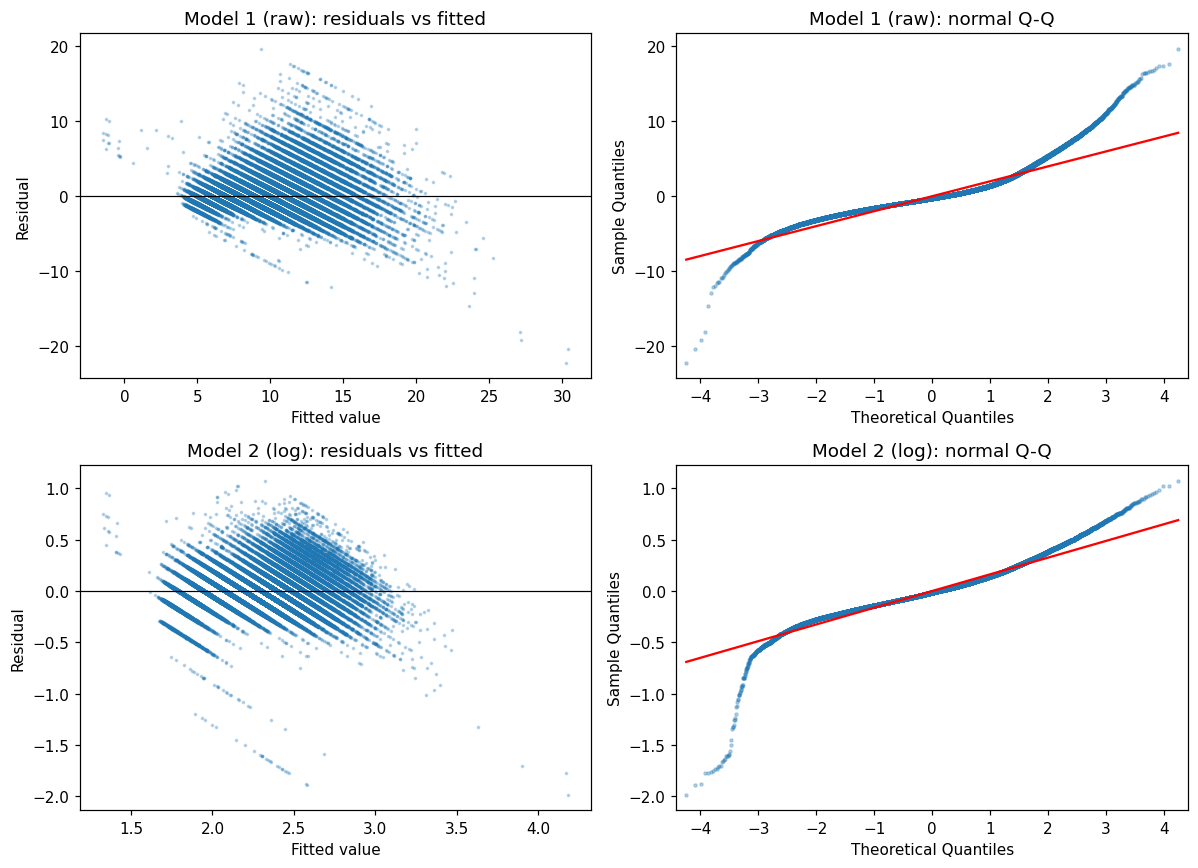

                 bp_stat  bp_p      dw      jb_stat    skew  kurtosis
Model 1 (raw)  8621.9846   0.0  1.9988  193061.4805  1.4328    9.5515
Model 2 (log)  4092.4186   0.0  1.9960  106384.0474  0.2442    8.2856

Variance inflation factors (Model 1 predictors):
length        51.2
diameter      54.3
height         7.8
whole_wt      69.2
shucked_wt    21.5
viscera_wt    20.1
shell_wt      18.4
sex_I          2.4
sex_M          1.4
Name: VIF, dtype: float64

Correlation of each measurement with log(1+Rings):
            pearson_log  spearman_log
length            0.716         0.708
diameter          0.726         0.720
height            0.735         0.757
whole_wt          0.674         0.736
shucked_wt        0.584         0.662
viscera_wt        0.648         0.724
shell_wt          0.736         0.787


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
resid_panel(m1.fittedvalues, m1.resid, "Model 1 (raw)", ax[0])
resid_panel(m2.fittedvalues, m2.resid, "Model 2 (log)", ax[1])
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "A2_fig_residuals.png"), dpi=150); plt.show()

d1, d2 = diagnostics(m1.resid, X), diagnostics(m2.resid, X2)
diag = pd.DataFrame({"Model 1 (raw)": d1, "Model 2 (log)": d2}).T
print(diag.round(4))

vif = pd.Series([variance_inflation_factor(sm.add_constant(X).values, i + 1) for i in range(X.shape[1])],
                index=X.columns, name="VIF")
print("\nVariance inflation factors (Model 1 predictors):"); print(vif.round(1))

# Linearity: compare each measurement against log rings (Spearman is rank-based, so it ignores curvature)
lin = pd.DataFrame({"pearson_log": [np.corrcoef(X[c], ylog)[0, 1] for c in NUM],
                    "spearman_log": [pd.Series(X[c]).corr(ylog, method="spearman") for c in NUM]}, index=NUM)
print("\nCorrelation of each measurement with log(1+Rings):"); print(lin.round(3))

In [8]:
from sklearn.linear_model import LinearRegression
cv1 = cv_rmsle(LinearRegression(), X, target="raw")
cv2 = cv_rmsle(LinearRegression(), X2, target="log")
print(f"5-fold CV RMSLE  Model 1 (raw OLS): {cv1:.5f}")
print(f"5-fold CV RMSLE  Model 2 (log OLS + interaction): {cv2:.5f}")

pred1 = np.asarray(m1.predict(sm.add_constant(X_test, has_constant="add")))
pred2 = np.expm1(np.asarray(m2.predict(sm.add_constant(X2_test, has_constant="add"))))
write_submission(pred1, "A2_model1_ols_raw.csv")
write_submission(pred2, "A2_model2_ols_log_interaction.csv")

RESULTS_FILE = "A2_results.json"
RESULTS["m1"] = {"r2": m1.rsquared, "adjr2": m1.rsquared_adj, "rse": float(np.sqrt(m1.scale)), "cv_rmsle": cv1,
                 "coef": m1.params.round(4).to_dict(), "p": m1.pvalues.to_dict(), **d1}
RESULTS["m2"] = {"r2": m2.rsquared, "adjr2": m2.rsquared_adj, "rse": float(np.sqrt(m2.scale)), "cv_rmsle": cv2,
                 "coef": m2.params.round(4).to_dict(), "p": m2.pvalues.to_dict(), **d2}
RESULTS["vif"] = vif.round(2).to_dict()
RESULTS["lin"] = lin.round(4).to_dict()
RESULTS["share_neg_pred_m1"] = float((pred1 < 1).mean())

5-fold CV RMSLE  Model 1 (raw OLS): 0.16377
5-fold CV RMSLE  Model 2 (log OLS + interaction): 0.16275
saved /content/drive/MyDrive/DDS8555/output/A2_model1_ols_raw.csv (60411, 2)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved /content/drive/MyDrive/DDS8555/output/A2_model2_ols_log_interaction.csv (60411, 2)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# ---- Plain-language reading of the results (printed from the numbers above) ----
better = "Model 2" if cv2 < cv1 else "Model 1"
print(f"* {better} predicts better: CV RMSLE {min(cv1, cv2):.4f} vs {max(cv1, cv2):.4f}.")
ratio = d1['bp_stat'] / max(d2['bp_stat'], 1e-9)
print(f"* Constant variance: the Breusch-Pagan statistic is {d1['bp_stat']:.0f} for the raw model and {d2['bp_stat']:.0f} for the log model "
      f"({'smaller' if d2['bp_stat'] < d1['bp_stat'] else 'larger'} on the log scale). The raw model's residuals fan out as fitted values grow.")
print(f"* Normality: residual skew {d1['skew']:.2f} (raw) vs {d2['skew']:.2f} (log); kurtosis {d1['kurtosis']:.2f} vs {d2['kurtosis']:.2f}.")
print(f"* Independence: Durbin-Watson {d1['dw']:.2f} and {d2['dw']:.2f} (2 means no lag-1 autocorrelation).")
print(f"* Collinearity: the largest VIF is {vif.max():.0f} ({vif.idxmax()}). The weight and size measurements are nearly redundant, "
      "so individual coefficients (including negative weight coefficients) should not be read as causal effects.")

* Model 2 predicts better: CV RMSLE 0.1628 vs 0.1638.
* Constant variance: the Breusch-Pagan statistic is 8622 for the raw model and 4092 for the log model (smaller on the log scale). The raw model's residuals fan out as fitted values grow.
* Normality: residual skew 1.43 (raw) vs 0.24 (log); kurtosis 9.55 vs 8.29.
* Independence: Durbin-Watson 2.00 and 2.00 (2 means no lag-1 autocorrelation).
* Collinearity: the largest VIF is 69 (whole_wt). The weight and size measurements are nearly redundant, so individual coefficients (including negative weight coefficients) should not be read as causal effects.


In [10]:
# ---- Results used in the paper (printed so they are saved in the notebook) ----
def _clean(o):
    if isinstance(o, dict):
        return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o
RESULTS = _clean(RESULTS)
with open(os.path.join(OUT_DIR, RESULTS_FILE), "w") as f:
    json.dump(RESULTS, f, indent=1)
print("RESULTS_JSON_START")
print(json.dumps(RESULTS))
print("RESULTS_JSON_END")

RESULTS_JSON_START
{"carseats": {"r2_a": 0.23927539218405558, "r2_e": 0.23926288842678567, "adjr2_a": 0.2335123269733287, "adjr2_e": 0.23543045965311715, "rse_a": 2.4724924402701642, "rse_e": 2.469396800574444, "urban_p": 0.9357389376375365, "max_lev_ratio": 5.778354271623848, "max_abs_sr": 2.891521318630446}, "data": {"n_train": 90615, "n_test": 60411, "zero_height_train": 6, "zero_height_test": 2, "missing_train": 0, "rings_min": 1.0, "rings_max": 29.0, "rings_mean": 9.696794129007339, "rings_skew": 1.2042729726026435}, "m1": {"r2": 0.6055736254488395, "adjr2": 0.6055344461831151, "rse": 1.9948729786235875, "cv_rmsle": 0.16376692406510907, "coef": {"const": 3.8452, "length": -2.0788, "diameter": 8.0545, "height": 21.1819, "whole_wt": 3.7775, "shucked_wt": -15.8093, "viscera_wt": -7.0219, "shell_wt": 20.7396, "sex_I": -0.717, "sex_M": -0.0148}, "p": {"const": 0.0, "length": 2.2000759861935414e-07, "diameter": 1.000044335674058e-58, "height": 0.0, "whole_wt": 1.252751045319679e-214, "s